In [ ]:
import warnings

warnings.filterwarnings("ignore")

In [ ]:
import pandas as pd
import etna
import gluonts

from etna.datasets import TSDataset

In [ ]:
df = pd.read_csv("https://raw.githubusercontent.com/etna-team/etna/refs/heads/master/examples/data/example_dataset.csv")
df.head()

,timestamp,segment,target
0,2019-01-01,segment_a,170
1,2019-01-02,segment_a,243
2,2019-01-03,segment_a,267
3,2019-01-04,segment_a,287
4,2019-01-05,segment_a,279


In [ ]:
ts = TSDataset(df, freq="D")
ts.head(5)

segment,segment_a,segment_b,segment_c,segment_d
feature,target,target,target,target
timestamp,,,,
2019-01-01,170.0,102.0,92.0,238.0
2019-01-02,243.0,123.0,107.0,358.0
2019-01-03,267.0,130.0,103.0,366.0
2019-01-04,287.0,138.0,103.0,385.0
2019-01-05,279.0,137.0,104.0,384.0


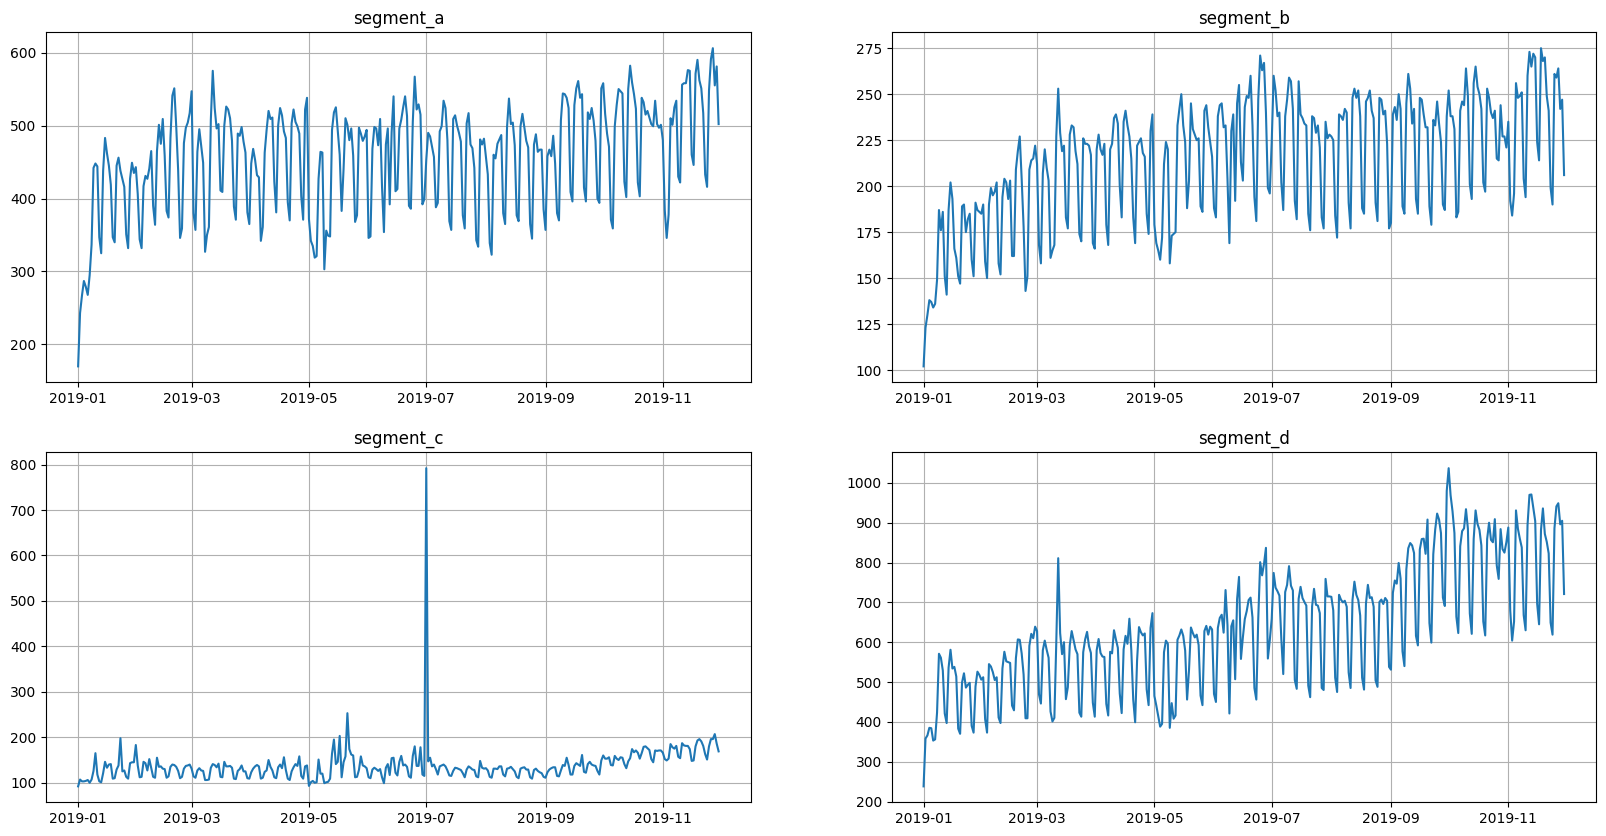

In [ ]:
ts.plot()

In [ ]:
HORIZON = 14

train_ts, test_ts = ts.train_test_split(test_size=HORIZON)

In [ ]:
from gluonts.dataset.pandas import PandasDataset

ds = PandasDataset.from_long_dataframe(train_ts.to_pandas(flatten=True).set_index("timestamp"), target="target", item_id="segment")

Получили датасет в формате GluonTS

In [ ]:
ds

PandasDataset<size=4, freq=D, num_feat_dynamic_real=0, num_past_feat_dynamic_real=0, num_feat_static_real=0, num_feat_static_cat=0, static_cardinalities=[]>

In [ ]:
from gluonts.torch.model.deepar import DeepAREstimator, DeepARModel, DeepARLightningModule
import torch
from pytorch_lightning import Trainer

estimator = DeepAREstimator(
    freq=ds.freq, prediction_length=HORIZON,
    trainer_kwargs=dict(max_epochs=10, accelerator="gpu")
)

predictor = estimator.train(ds)

INFO:pytorch_lightning.utilities.rank_zero:GPU available: True (cuda), used: True
INFO:pytorch_lightning.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO:pytorch_lightning.utilities.rank_zero:HPU available: False, using: 0 HPUs
INFO: LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO:lightning.pytorch.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO: 
  | Name  | Type        | Params | Mode  | In sizes                                                         | Out sizes   
--------------------------------------------------------------------------------------------------------------------------------
0 | model | DeepARModel | 25.9 K | train | [[1, 1], [1, 1], [1, 1106, 4], [1, 1106], [1, 1106], [1, 14, 4]] | [1, 100, 14]
--------------------------------------------------------------------------------------------------------------------------------
25.9 K    Trainable params
0         Non-trainable params
25.9 K    Total params
0.104     Total estimated model 

Training: |          | 0/? [00:00<?, ?it/s]

INFO:pytorch_lightning.utilities.rank_zero:Epoch 0, global step 50: 'train_loss' reached 6.28232 (best 6.28232), saving model to '/content/lightning_logs/version_0/checkpoints/epoch=0-step=50.ckpt' as top 1
INFO:pytorch_lightning.utilities.rank_zero:Epoch 1, global step 100: 'train_loss' reached 5.26432 (best 5.26432), saving model to '/content/lightning_logs/version_0/checkpoints/epoch=1-step=100.ckpt' as top 1
INFO:pytorch_lightning.utilities.rank_zero:Epoch 2, global step 150: 'train_loss' reached 5.01786 (best 5.01786), saving model to '/content/lightning_logs/version_0/checkpoints/epoch=2-step=150.ckpt' as top 1
INFO:pytorch_lightning.utilities.rank_zero:Epoch 3, global step 200: 'train_loss' reached 4.76389 (best 4.76389), saving model to '/content/lightning_logs/version_0/checkpoints/epoch=3-step=200.ckpt' as top 1
INFO:pytorch_lightning.utilities.rank_zero:Epoch 4, global step 250: 'train_loss' reached 4.70976 (best 4.70976), saving model to '/content/lightning_logs/version_0/c

В gluonts две основных сущности: `estimator` и `predictor`.

В `predictor` можно использовать для inference как отдельную сущность

In [ ]:
?estimator.create_transformation

```python
def create_transformation(self) -> Transformation:
        remove_field_names = []
        if self.num_feat_static_real == 0:
            remove_field_names.append(FieldName.FEAT_STATIC_REAL)
        if self.num_feat_dynamic_real == 0:
            remove_field_names.append(FieldName.FEAT_DYNAMIC_REAL)

        return Chain(
            [RemoveFields(field_names=remove_field_names)]
            + (
                [SetField(output_field=FieldName.FEAT_STATIC_CAT, value=[0])]
                if not self.num_feat_static_cat > 0
                else []
            )
            + (
                [
                    SetField(
                        output_field=FieldName.FEAT_STATIC_REAL, value=[0.0]
                    )
                ]
                if not self.num_feat_static_real > 0
                else []
            )
            + [
                AsNumpyArray(
                    field=FieldName.FEAT_STATIC_CAT,
                    expected_ndim=1,
                    dtype=int,
                ),
                AsNumpyArray(
                    field=FieldName.FEAT_STATIC_REAL,
                    expected_ndim=1,
                ),
                AsNumpyArray(
                    field=FieldName.TARGET,
                    # in the following line, we add 1 for the time dimension
                    expected_ndim=1 + len(self.distr_output.event_shape),
                ),
                AddObservedValuesIndicator(
                    target_field=FieldName.TARGET,
                    output_field=FieldName.OBSERVED_VALUES,
                    imputation_method=self.imputation_method,
                ),
                AddTimeFeatures(
                    start_field=FieldName.START,
                    target_field=FieldName.TARGET,
                    output_field=FieldName.FEAT_TIME,
                    time_features=self.time_features,
                    pred_length=self.prediction_length,
                ),
                AddAgeFeature(
                    target_field=FieldName.TARGET,
                    output_field=FieldName.FEAT_AGE,
                    pred_length=self.prediction_length,
                    log_scale=True,
                ),
                VstackFeatures(
                    output_field=FieldName.FEAT_TIME,
                    input_fields=[FieldName.FEAT_TIME, FieldName.FEAT_AGE]
                    + (
                        [FieldName.FEAT_DYNAMIC_REAL]
                        if self.num_feat_dynamic_real > 0
                        else []
                    ),
                ),
                AsNumpyArray(FieldName.FEAT_TIME, expected_ndim=2),
            ]
        )
```

In [ ]:
estimator.time_features

[<function gluonts.time_feature._base.day_of_week(index: pandas.core.indexes.period.PeriodIndex) -> numpy.ndarray>,
 <function gluonts.time_feature._base.day_of_month(index: pandas.core.indexes.period.PeriodIndex) -> numpy.ndarray>,
 <function gluonts.time_feature._base.day_of_year(index: pandas.core.indexes.period.PeriodIndex) -> numpy.ndarray>]

In [ ]:
gluon_ts_predictions = []
for sample in predictor.predict(ds):
  mean_ = sample.mean
  df = pd.DataFrame(
      {"timestamp": pd.date_range(start=sample.start_date.to_timestamp(), freq=sample.start_date.freq.delta, periods=HORIZON), "target": mean_}
  )
  df["segment"] = sample.item_id
  gluon_ts_predictions.append(df)

In [ ]:
gluon_ts_predictions = TSDataset(pd.concat(gluon_ts_predictions), "D")

In [ ]:
from etna.analysis import plot_forecast

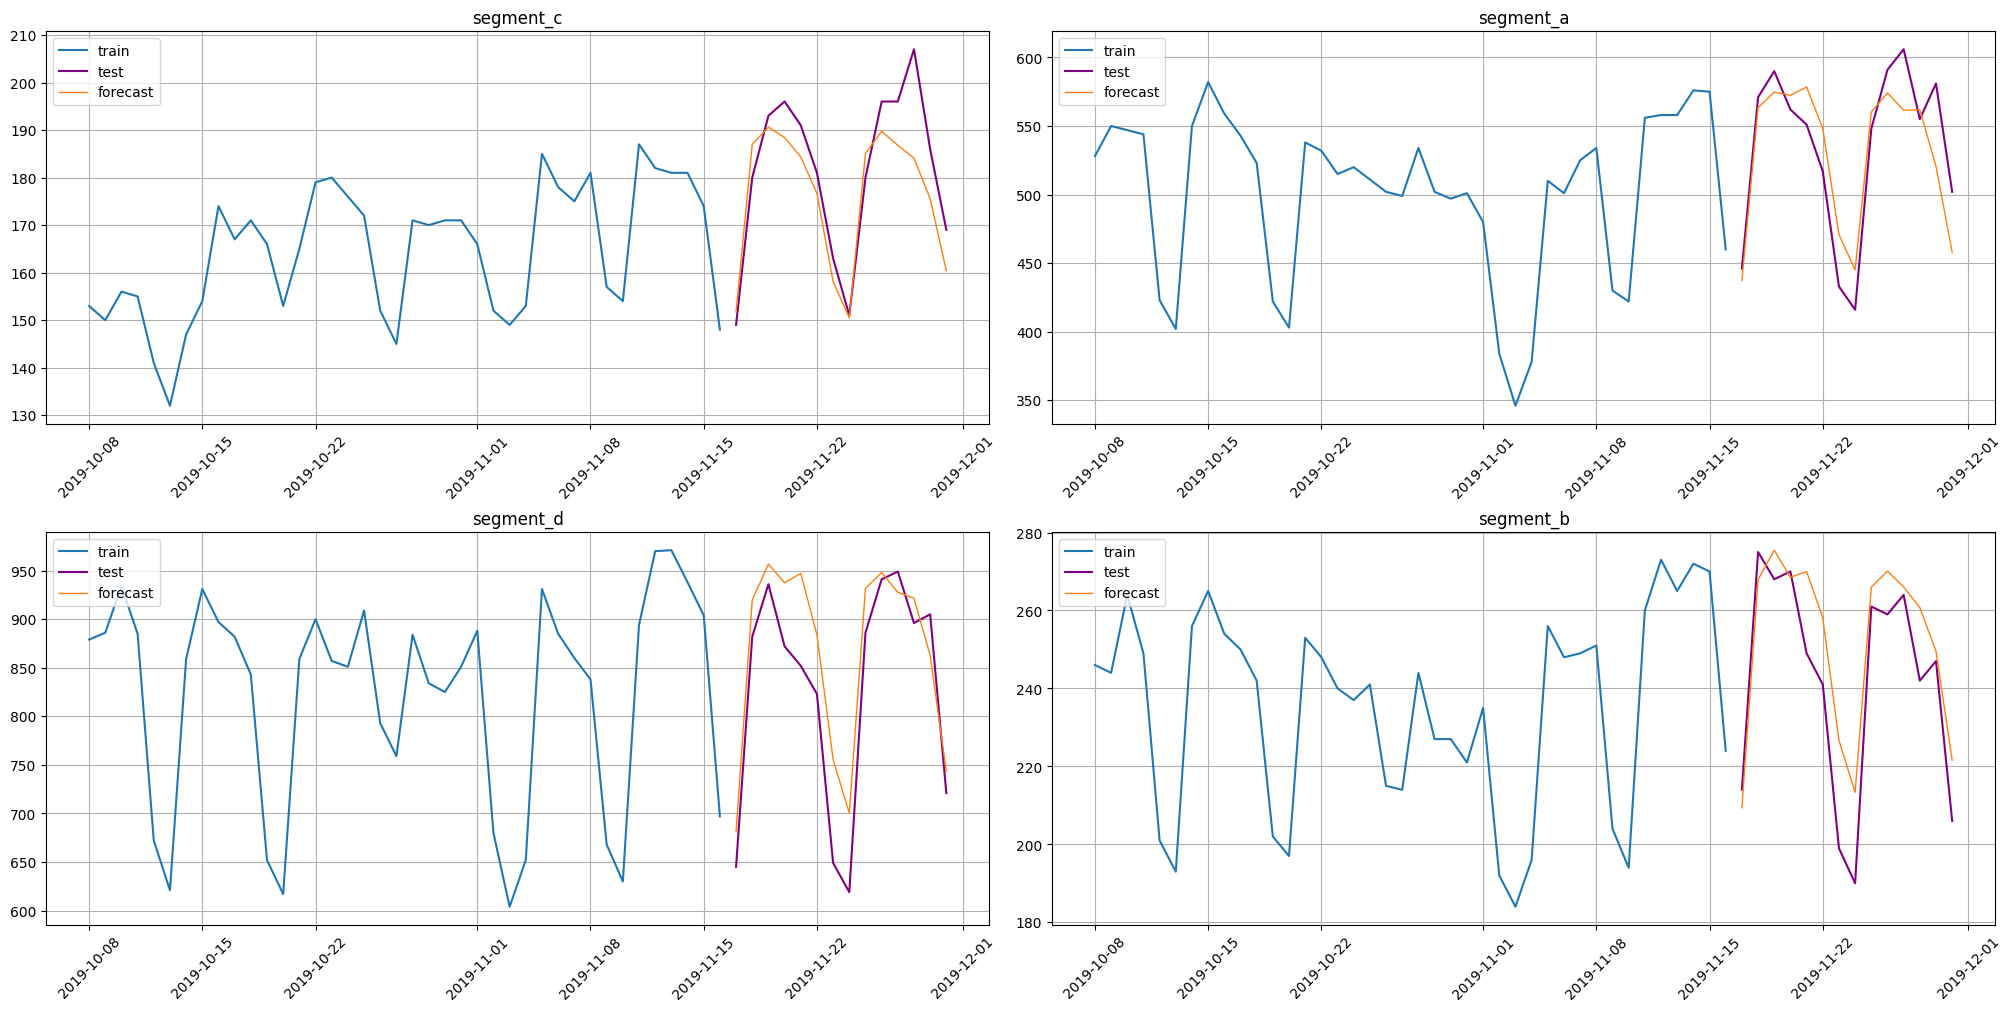

In [ ]:
plot_forecast(
    gluon_ts_predictions, test_ts, train_ts, n_train_samples=40
)

In [ ]:
from etna.models.nn import DeepARModel
from etna.transforms import LagTransform, StandardScalerTransform, DateFlagsTransform, LabelEncoderTransform
from etna.pipeline import Pipeline
from copy import deepcopy

In [ ]:
scaler = StandardScalerTransform(in_column="target")
transform_date = DateFlagsTransform(
    day_number_in_week=True,
    day_number_in_month=False,
    day_number_in_year=False,
    week_number_in_month=False,
    week_number_in_year=False,
    month_number_in_year=False,
    season_number=False,
    year_number=False,
    is_weekend=False,
    out_column="dateflag",
)

label_encoder = LabelEncoderTransform(
    in_column="dateflag_day_number_in_week", strategy="none", out_column="dateflag_day_number_in_week_label"
)

embedding_sizes = {"dateflag_day_number_in_week_label": (7, 7)}

deep_etna = Pipeline(
    DeepARModel(
        input_size=1, encoder_length=HORIZON*3, decoder_length=HORIZON,
        scale=False,
        embedding_sizes=embedding_sizes,
        trainer_params=dict(max_epochs=10, accelerator="gpu"),
        lr=0.01,
    ), horizon=HORIZON
    ,
    transforms=[scaler, transform_date, label_encoder],
)

In [ ]:
deep_etna.fit(deepcopy(train_ts))

INFO:pytorch_lightning.utilities.rank_zero:GPU available: True (cuda), used: True
INFO:pytorch_lightning.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO:pytorch_lightning.utilities.rank_zero:HPU available: False, using: 0 HPUs
INFO: LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO:lightning.pytorch.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO: 
  | Name       | Type           | Params | Mode 
------------------------------------------------------
0 | loss       | GaussianLoss   | 0      | train
1 | embedding  | MultiEmbedding | 56     | train
2 | rnn        | LSTM           | 3.8 K  | train
3 | projection | ModuleDict     | 34     | train
------------------------------------------------------
3.9 K     Trainable params
0         Non-trainable params
3.9 K     Total params
0.016     Total estimated model params size (MB)
11        Modules in train mode
0         Modules in eval mode
INFO:lightning.pytorch.callbacks.model_summary:
  | Name       | Type

Training: |          | 0/? [00:00<?, ?it/s]

INFO:pytorch_lightning.utilities.rank_zero:`Trainer.fit` stopped: `max_epochs=10` reached.


Pipeline(model = DeepARModel(input_size = 1, encoder_length = 42, decoder_length = 14, num_layers = 2, dropout = 0.0, hidden_size = 16, embedding_sizes = {'dateflag_day_number_in_week_label': (7, 7)}, lr = 0.01, scale = False, n_samples = 1, loss = None, train_batch_size = 16, test_batch_size = 16, optimizer_params = None, trainer_params = {'max_epochs': 10, 'accelerator': 'gpu', 'logger': []}, train_dataloader_params = {}, test_dataloader_params = {}, val_dataloader_params = {}, split_params = {}, ), transforms = [StandardScalerTransform(in_column = ['target'], inplace = True, out_column = None, with_mean = True, with_std = True, mode = 'per-segment', ), DateFlagsTransform(day_number_in_week = True, day_number_in_month = False, day_number_in_year = False, week_number_in_month = False, week_number_in_year = False, month_number_in_year = False, season_number = False, year_number = False, is_weekend = False, special_days_in_week = (), special_days_in_month = (), out_column = 'dateflag', 

In [ ]:
etna_ts_prediction = deep_etna.forecast(deepcopy(train_ts))

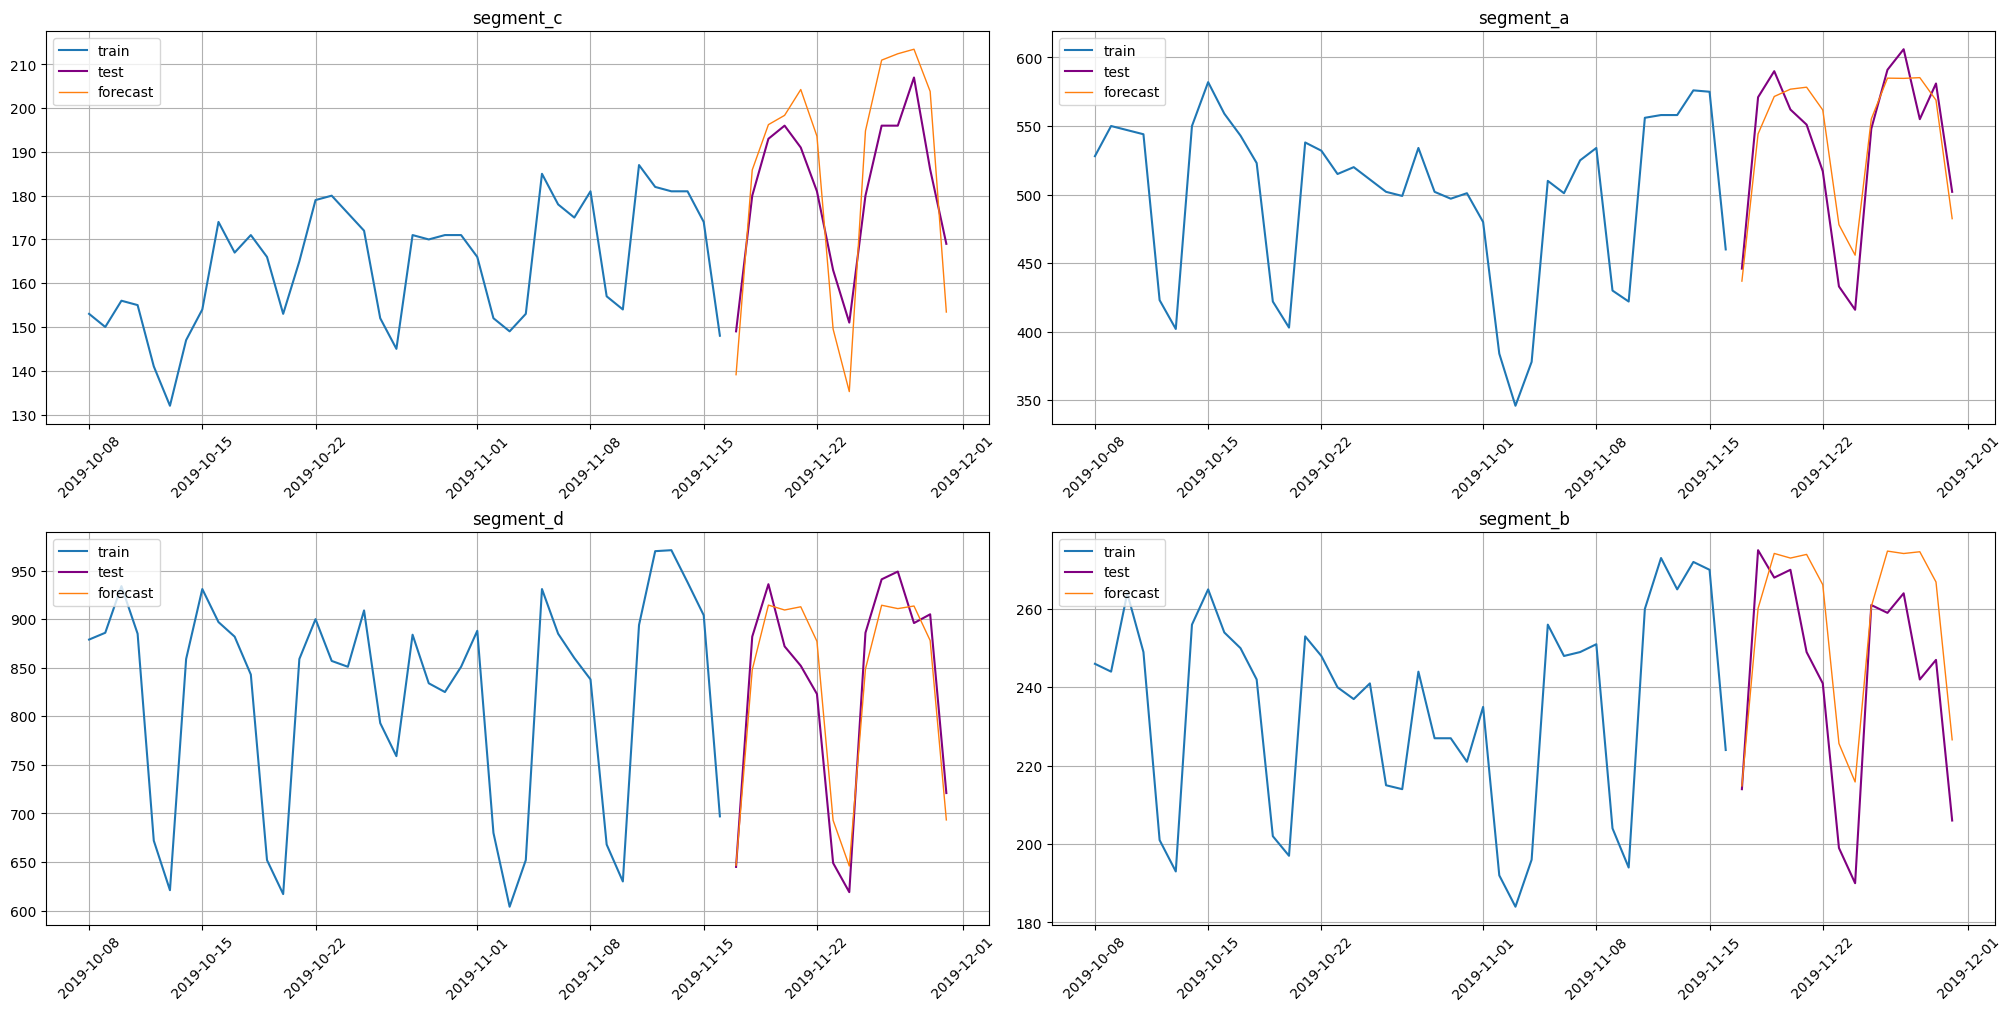

In [ ]:
plot_forecast(
    etna_ts_prediction, test_ts, train_ts, n_train_samples=40
)

In [ ]:
from etna.metrics import SMAPE, MAE

In [ ]:
SMAPE()(test_ts, etna_ts_prediction)

{'segment_a': 4.434181534799265,
 'segment_b': 6.699768723374358,
 'segment_c': 6.514759183198381,
 'segment_d': 3.9227828092900325}

In [ ]:
SMAPE()(test_ts, gluon_ts_predictions)

{'segment_a': 4.831822435760066,
 'segment_b': 5.017606164257438,
 'segment_c': 3.8417827093109294,
 'segment_d': 5.923074043817398}